# 02 · Forwarding graph and communities

Builds the channel forwarding graph from `tgdata/forwards/`, describes it, and detects communities with
Leiden. The communities are the boundary for **RQ1** (which topics cross community boundaries).

**Conventions** (see `docs/PROJECT_CONTEXT.md` §5 and `docs/DECISIONS.md`)
- **Edge direction is content flow: `src_id -> dest_id`**: the message was written in `src_id` and
  reposted in `dest_id`. So *out-strength* = how often a channel was reposted by others, and
  *in-strength* = how much a channel reposted.
- Edge weight = number of forwards. Nodes are TGDataset channels. Forwards with a hidden sender, a source
  outside the dataset, or `src_id = dest_id` are dropped.
- Leiden: `RBConfigurationVertexPartition`, resolution 1.0, directed, weighted, seed 42, run until
  convergence.

**Outputs**
| File | Content |
|---|---|
| `tgdata/derived/edges_full.parquet` | edges of the full graph (all languages) |
| `tgdata/derived/edges_en.parquet` | edges with English source and destination |
| `tgdata/derived/communities.parquet` | `channel_id, community` (0 = largest) |
| `tgdata/derived/communities_meta.json` | Leiden settings, seed, modularity, versions |
| `results/02_*.csv`, `results/02_*.png/.svg` | tables and figures |

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, graph, plots

plots.use_style()
pd.set_option("display.max_colwidth", 80, "display.width", 200)
cfg.RESULTS.mkdir(exist_ok=True)

con = data.connect()
channels = data.channel_table(con)
print(f"channels: {len(channels):,}")
print(f"  with a language label: {channels.language.notna().sum():,}; English: {(channels.language == 'en').sum():,}")
print(f"  conspiracy: {channels.conspiracy.sum():,} "
      f"(label file lists {con.sql('SELECT count(*) FROM consp').fetchone()[0]:,} ids); "
      f"Sabmyk: {channels.sabmyk.sum():,}")

channels: 120,979
  with a language label: 97,674; English: 19,768
  conspiracy: 11,618 (label file lists 11,618 ids); Sabmyk: 236


## 1 · Edge tables

One DuckDB query aggregates the 93.4M forwards into one row per `(src_id, dest_id)` pair. The
English–English table is a filter of the full one (same result as filtering forwards first, because the
aggregation is per pair). If the files already exist they are reused; pass `overwrite=True` to rebuild.
The counts are checked against the figures verified at extraction time (`PROJECT_CONTEXT.md` §4.2).

In [2]:
t0 = time.time()
paths = data.build_edges(con)
edges = pd.read_parquet(paths["full"])
edges_en = pd.read_parquet(paths["en"])
print(f"edge tables ready in {time.time() - t0:.0f} s")

def counts(e):
    return len(np.union1d(e.src_id, e.dest_id)), len(e), int(e.weight.sum())

assert counts(edges) == (120_715, 4_676_642, 57_947_677), counts(edges)
assert counts(edges_en) == (18_216, 785_846, 13_166_079), counts(edges_en)
for name, e in [("full", edges), ("English-English", edges_en)]:
    n, m, w = counts(e)
    print(f"{name:>16}: {n:,} nodes, {m:,} edges, {w:,} forwards "
          f"({e.n_text.sum():,} text, {e.n_media.sum():,} media)")
edges.head()

edge tables ready in 0 s


            full: 120,715 nodes, 4,676,642 edges, 57,947,677 forwards (34,302,930 text, 23,644,747 media)
 English-English: 18,216 nodes, 785,846 edges, 13,166,079 forwards (7,731,006 text, 5,435,073 media)


,src_id,dest_id,weight,n_text,n_media,first_date,last_date
0,1000000882,1006655022,10,7,3,1512470354,1527497030
1,1000000882,1242641762,6,6,0,1546054851,1554016852
2,1000002626,1152377311,2,2,0,1549654451,1558798769
3,1000002626,1431775624,1,1,0,1621795038,1621795038
4,1000004063,1016472602,1,1,0,1506336067,1506336067


## 2 · Graph descriptives

Both graphs side by side: the full graph (where communities are detected) and the English–English graph
(where topics will be assigned). Reciprocity is given per edge (share of edges whose reverse exists) and
per forward (`Σ min(w_ij, w_ji) / Σ w_ij`).

In [3]:
g = graph.to_igraph(edges)
g_en = graph.to_igraph(edges_en)

summary = pd.DataFrame({"full": graph.graph_summary(edges, g),
                        "english_english": graph.graph_summary(edges_en, g_en)})
summary.to_csv(cfg.RESULTS / "02_graph_summary.csv")
summary.style.format(lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.4f}")

,full,english_english
nodes,"120,715","18,216"
edges,"4,676,642","785,846"
forwards,"57,947,677","13,166,079"
text_forwards_share,0.5920,0.5872
density,0.0003,0.0024
mean_out_degree,38.7412,43.1404
reciprocity_edges,0.1863,0.1479
reciprocity_weighted,0.1196,0.0990
wcc_count,5.0000,59.0000
largest_wcc_share,0.9999,0.9918


In [4]:
nodes = graph.node_table(edges)
nodes_en = graph.node_table(edges_en)

def concentration(n):
    s = n.out_strength.to_numpy()
    a = graph.top_share(s)
    b = graph.top_share(s[s > 0])
    return pd.DataFrame({"all graph nodes": a, "channels reposted ≥ 1 time": b}).rename(
        index=lambda f: f"top {f:.0%} of sources")

conc = pd.concat({"full": concentration(nodes), "english_english": concentration(nodes_en)}, axis=1)
conc.to_csv(cfg.RESULTS / "02_concentration.csv")
print(f"full graph: {len(nodes):,} nodes, {(nodes.out_strength > 0).sum():,} reposted at least once")
print("Share of channel-to-channel forwards whose source is among the top x% of channels by out-strength:")
conc.style.format("{:.1%}")

full graph: 120,715 nodes, 120,478 reposted at least once
Share of channel-to-channel forwards whose source is among the top x% of channels by out-strength:


**Figure 1.** Degree, strength and edge-weight distributions as complementary CDFs (P(X ≥ x), log–log),
plus the concentration curve. Edge direction: content flow, `src -> dest`. Out = reposted by others,
in = reposting others.

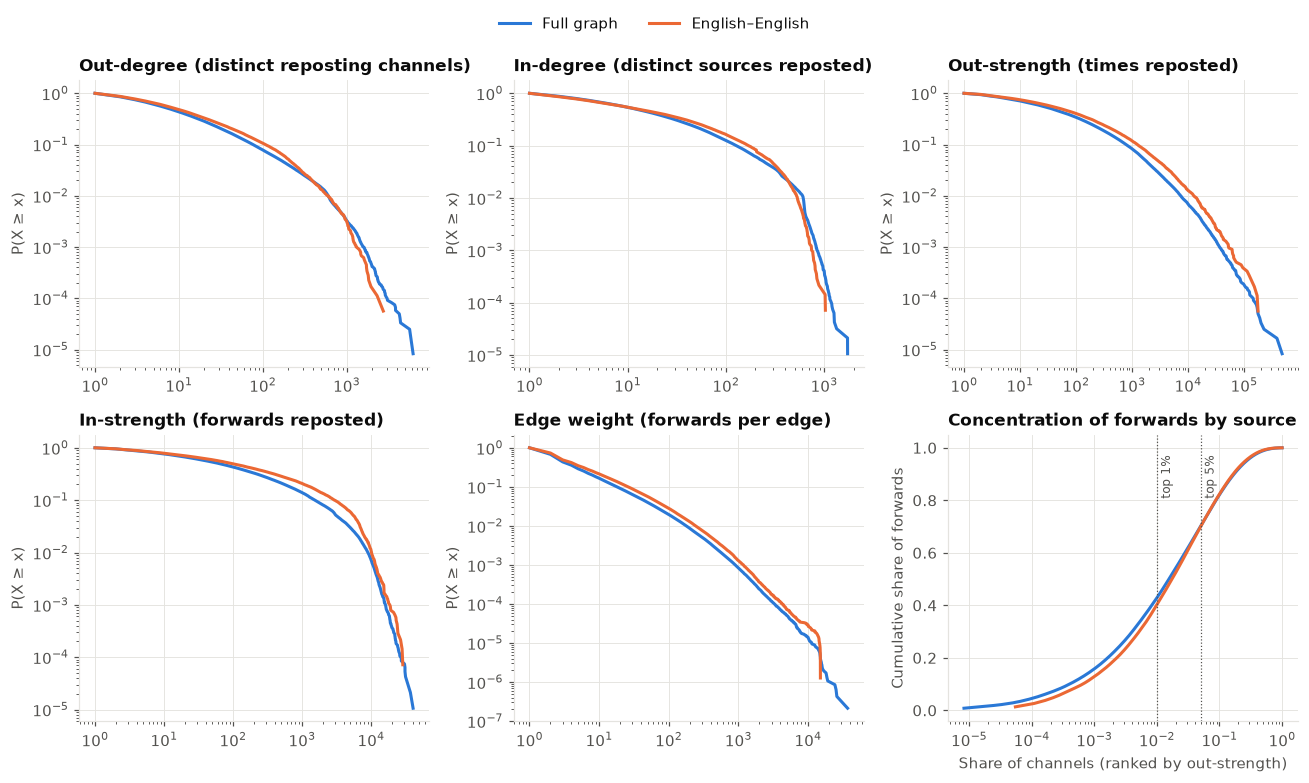

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
panels = [("out_degree", "Out-degree (distinct reposting channels)"),
          ("in_degree", "In-degree (distinct sources reposted)"),
          ("out_strength", "Out-strength (times reposted)"),
          ("in_strength", "In-strength (forwards reposted)")]
series = [("Full graph", nodes, edges, plots.SERIES[0]),
          ("English–English", nodes_en, edges_en, plots.SERIES[1])]
for ax, (col, title) in zip(axes.flat, panels):
    for label, n, _, c in series:
        x, y = graph.ccdf(n[col].to_numpy())
        ax.loglog(x, y, color=c, label=label)
    ax.set_title(title, loc="left"); ax.set_ylabel("P(X ≥ x)")
ax = axes.flat[4]
for label, _, e, c in series:
    x, y = graph.ccdf(e.weight.to_numpy())
    ax.loglog(x, y, color=c, label=label)
ax.set_title("Edge weight (forwards per edge)", loc="left"); ax.set_ylabel("P(X ≥ x)")
ax = axes.flat[5]
for label, n, _, c in series:
    s = np.sort(n.out_strength.to_numpy())[::-1]
    frac = np.arange(1, len(s) + 1) / len(s)
    ax.semilogx(frac, np.cumsum(s) / s.sum(), color=c, label=label)
for f in (0.01, 0.05):
    ax.axvline(f, color=plots.INK_2, lw=0.8, ls=":")
    ax.text(f * 1.15, 0.97, f"top {f:.0%}", color=plots.INK_2, fontsize=8, rotation=90, va="top")
ax.set_title("Concentration of forwards by source", loc="left")
ax.set_xlabel("Share of channels (ranked by out-strength)"); ax.set_ylabel("Cumulative share of forwards")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.97))
plots.savefig(fig, "02_fig1_distributions")
plt.show()

**Most reposted channels** (top 15 by out-strength in the full graph): the channels whose content travels
furthest by volume. `reposted_by` = number of distinct channels that reposted them.

In [6]:
info = channels.set_index("channel_id")[["username", "title", "language", "ch_topic", "conspiracy", "n_subscribers"]]
top_src = (nodes.nlargest(15, "out_strength").set_index("channel_id")
           .join(info)[["username", "language", "ch_topic", "conspiracy", "out_strength", "out_degree", "n_subscribers"]]
           .rename(columns={"out_strength": "times_reposted", "out_degree": "reposted_by"}))
top_src.to_csv(cfg.RESULTS / "02_top_sources.csv")
top_src

,username,language,ch_topic,conspiracy,times_reposted,reposted_by,n_subscribers
channel_id,,,,,,,
1139528163,shmirziyoyev,ru,NaN,False,477192,2705,184112
1296087183,mafia_7ru,ru,NaN,False,386443,1034,7489
1353291112,porno_politika,ru,NaN,False,226919,1014,30513
1179270258,disclosetv,en,World news,False,200295,4402,446212
1394050290,bbbreaking,ru,NaN,False,190115,6203,746648
1305795976,TheBL1,en,US news,False,177794,462,14730
1479163323,TommyRobinsonNews,en,US news,True,173781,3828,157058
1303844417,sol_cremly,ru,NaN,False,171043,976,6494
1285160972,QlobalChange,de,NaN,True,166240,1879,139816


## 3 · Leiden communities (full graph)

Settings fixed in advance: `RBConfigurationVertexPartition` (resolution 1.0, i.e. modularity), directed,
weighted, seed 42, iterate until no improvement (`docs/DECISIONS.md` D1). Communities are renumbered by
size (D3). The directed modularity is the main figure; the undirected modularity of the same partition is
shown for comparison with TGDataset's reported 0.78 (D4).

In [7]:
membership, meta = graph.leiden(g)
comm = pd.DataFrame({"channel_id": np.asarray(g.vs["channel_id"], dtype="int64"),
                     "community": membership.astype("int32")})
comm.to_parquet(cfg.DERIVED / "communities.parquet", index=False)
(cfg.DERIVED / "communities_meta.json").write_text(json.dumps(meta, indent=2))
(cfg.RESULTS / "02_leiden_run.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "algorithm": "leidenalg.RBConfigurationVertexPartition",
  "resolution": 1.0,
  "seed": 42,
  "n_iterations": -1,
  "directed": true,
  "weighted": true,
  "nodes": 120715,
  "edges": 4676642,
  "n_communities": 289,
  "quality": 49949764.38903792,
  "modularity_directed": 0.8619804446869871,
  "modularity_undirected": 0.8619365195241062,
  "seconds": 128.6,
  "leidenalg_version": "0.12.0",
  "igraph_version": "1.0.0"
}


289 communities over 120,715 channels
  singletons: 0; with ≥ 10 channels: 74; ≥ 100: 34
  largest  5: 62.0% of channels; 37.7% of forwards have both ends in them
  largest 15: 89.4% of channels; 79.6% of forwards have both ends in them
  largest 50: 99.1% of channels; 98.3% of forwards have both ends in them


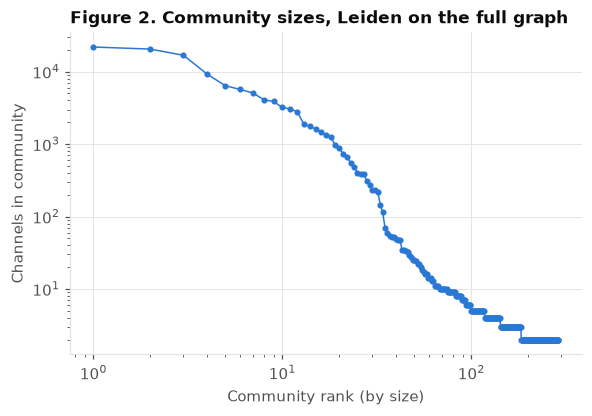

In [8]:
sizes = comm.community.value_counts().sort_index()
c_of = comm.set_index("channel_id").community
src_c, dst_c = edges.src_id.map(c_of).to_numpy(), edges.dest_id.map(c_of).to_numpy()
w = edges.weight.to_numpy()
TOP = 15

print(f"{len(sizes):,} communities over {len(comm):,} channels")
print(f"  singletons: {(sizes == 1).sum():,}; with ≥ 10 channels: {(sizes >= 10).sum():,}; ≥ 100: {(sizes >= 100).sum():,}")
for k in (5, 15, 50):
    both = (src_c < k) & (dst_c < k)
    print(f"  largest {k:>2}: {sizes.iloc[:k].sum() / len(comm):.1%} of channels; "
          f"{w[both].sum() / w.sum():.1%} of forwards have both ends in them")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(np.arange(1, len(sizes) + 1), sizes.to_numpy(), marker="o", ms=3, lw=1, color=plots.SERIES[0])
ax.set_xlabel("Community rank (by size)"); ax.set_ylabel("Channels in community")
ax.set_title("Figure 2. Community sizes, Leiden on the full graph", loc="left")
plots.savefig(fig, "02_fig2_community_sizes")
plt.show()

## 4 · What the communities are

For the 15 largest communities: languages, share of conspiracy-labeled channels, the channel-topic mix of
the English members (LDA labels from the dataset; available for English channels only), and the top
channels by out-strength (most reposted) and by HITS source score (hub score on the content-flow graph,
which equals the authority score in the citation direction used by Imperati et al.; computed inside each
community's subgraph; D5). `unk` = no language label. Forward counts:
*internal* = source and destination in the community; *exported* = source inside, destination outside;
*imported* = the reverse.

In [9]:
# HITS inside each community's subgraph (D5, amended): on the whole graph the leading eigenvector
# concentrates on one dense block and most communities get near-zero scores.
hub = np.full(g.vcount(), np.nan)
for c in range(TOP):
    idx = np.flatnonzero(membership == c)
    hub[idx] = g.induced_subgraph(idx.tolist()).hub_score(weights="weight")
ch = (comm.assign(hits_source=hub)
      .merge(nodes, on="channel_id")
      .merge(channels, on="channel_id", how="left"))

def mix(s, k=3):
    vc = s.fillna("unknown").value_counts(normalize=True).head(k)
    return ", ".join(f"{i} {v:.0%}" for i, v in vc.items())

def top_names(df, col, k=3):
    return ", ".join(df.nlargest(k, col).username.fillna("(no username)").astype(str))

rows = []
for c in range(TOP):
    m = ch[ch.community == c]
    en = m[m.language == "en"]
    rows.append({
        "community": c,
        "channels": len(m),
        "languages": mix(m.language),
        "conspiracy_share": m.conspiracy.mean(),
        "english_channels": len(en),
        "english_topics": mix(en.ch_topic.dropna()) if en.ch_topic.notna().any() else "",
        "forwards_internal": int(w[(src_c == c) & (dst_c == c)].sum()),
        "forwards_exported": int(w[(src_c == c) & (dst_c != c)].sum()),
        "forwards_imported": int(w[(src_c != c) & (dst_c == c)].sum()),
        "top_reposted": top_names(m, "out_strength"),
        "top_hits_source": top_names(m, "hits_source"),
        "top_reposters": top_names(m, "in_strength"),
    })
ctab = pd.DataFrame(rows).set_index("community")
ctab["internal_share_of_outgoing"] = ctab.forwards_internal / (ctab.forwards_internal + ctab.forwards_exported)
ctab.to_csv(cfg.RESULTS / "02_communities_top15.csv")
ctab.style.format({"conspiracy_share": "{:.0%}", "internal_share_of_outgoing": "{:.0%}",
                   "channels": "{:,}", "english_channels": "{:,}", "forwards_internal": "{:,}",
                   "forwards_exported": "{:,}", "forwards_imported": "{:,}"})

C:\Users\guilh\AppData\Local\Temp\ipykernel_24764\3598243452.py:6: RuntimeWarning: More than 30% of hub or authority scores are zeros. The presence of zero values indicates that the solution is not unique, thus the returned result may not be meaningful. Location: src/centrality/hub_authority.c:81
  hub[idx] = g.induced_subgraph(idx.tolist()).hub_score(weights="weight")


,channels,languages,conspiracy_share,english_channels,english_topics,forwards_internal,forwards_exported,forwards_imported,top_reposted,top_hits_source,top_reposters,internal_share_of_outgoing
community,,,,,,,,,,,,
0,"21,885","ru 94%, unknown 4%, en 1%",5%,203,"Videogame modding 31%, World news 20%, Software 9%","8,761,556","727,926","570,743","bbbreaking, rian_ru, dimsmirnov175","youlistenedmayak, bbbreaking, rian_ru","eshkinkrot, vrn_karaulny, stranoved",92%
1,"20,504","ru 68%, unknown 24%, en 4%",3%,761,"Religion 26%, Entertainment 25%, Software 17%","3,905,560","373,654","592,070","dvachannel, goldchihuahua, malzoffsgallery","afishadailynews, kinopoisk, afishadaily","summ3r_m0v3d_0n, dikultpohod, unitedmemesfeednolgbtandsjw",91%
2,"16,822","fa 94%, unknown 4%, en 1%",1%,138,"Religion 44%, Videogame modding 11%, Porn 8%","3,398,902","16,154","18,819","isna94, farsna, Tasnimnews","fartakvarzeshi, fartaknews, fartaknews_kermanshah","Cashaneh, lig_daily1, Talkhand_Siyasi",100%
3,"9,258","unknown 69%, ru 14%, bg 10%",0%,228,"Indian edu 46%, Religion 21%, Social 11%","3,337,071","11,759","21,182","shmirziyoyev, times_officialuz, eduuz","shmirziyoyev, Rasmiy_xabarlar_Official, times_officialuz","xivashahar, toshhetk, andijonarxiv",100%
4,"6,386","en 35%, unknown 34%, it 22%",4%,"2,225","Religion 41%, Entertainment 32%, Software 6%","1,648,772","194,367","117,970","dadoem_mv, AnimeBirthdays, PoliticalMemes","HourlyFoxes, YiffFactory, FurryFemboyCollection","zhiisgoddess, Dimitrisimpandpics, FurFavs",89%
5,"5,674","de 86%, unknown 9%, en 4%",51%,235,"Religion 22%, US news 20%, Covid 14%","7,679,404","125,277","516,222","QlobalChange, unzensiert, fufmedia","QlobalChange, fufmedia, Qparadise","Corona_Kingdom, Qanalwwg1wga, QV_TeamNews",98%
6,"5,067","en 78%, unknown 13%, es 2%",35%,"3,977","Religion 41%, Extremists and radicals 21%, US news 15%","2,357,818","379,255","448,100","HawGa, BellumActaNews, JackDawkins","therealityreport, usvoterfraud, vinniesullivan","(no username), LogosIsRising, NSDAPFrance",86%
7,"4,099","en 93%, unknown 4%, nl 1%",67%,"3,795","US news 51%, Covid 32%, Religion 11%","5,124,475","934,825","370,902","disclosetv, TommyRobinsonNews, realKarliBonne","realKarliBonne, TommyRobinsonNews, disclosetv","WeTheMedia, TierneyRealNews, BrittRepublican",85%
8,"3,878","en 81%, unknown 15%, ar 2%",1%,"3,144","Videogame modding 45%, Carding 43%, Software 6%","2,595,761","7,014","10,519","followersmart1, PUBG_ACCOUNT_OFFICAL, UC_SH0PS","followersmart1, tricksterhacker, PUBG_ACCOUNT_OFFICAL","Official_NoMercy, MAHAKAL_GAMER, DAILYHACKSPUBG",100%


**Where the conspiracy-labeled channels are.** Communities ranked by number of conspiracy channels. This is
descriptive only: RQ2 uses the label directly, not the communities.

In [10]:
in_graph = ch.conspiracy.sum()
print(f"conspiracy channels in the graph: {in_graph:,} of {channels.conspiracy.sum():,} labeled")
cons = (ch.groupby("community")
        .agg(channels=("channel_id", "size"), conspiracy=("conspiracy", "sum"),
             languages=("language", mix))
        .sort_values("conspiracy", ascending=False).head(10))
cons["share_of_all_conspiracy"] = cons.conspiracy / in_graph
cons["cumulative_share"] = cons.share_of_all_conspiracy.cumsum()
cons["conspiracy_share_of_community"] = cons.conspiracy / cons.channels
cons.to_csv(cfg.RESULTS / "02_conspiracy_by_community.csv")
cons.style.format({"share_of_all_conspiracy": "{:.1%}", "cumulative_share": "{:.1%}",
                   "conspiracy_share_of_community": "{:.0%}", "channels": "{:,}", "conspiracy": "{:,}"})

conspiracy channels in the graph: 11,615 of 11,618 labeled


,channels,conspiracy,languages,share_of_all_conspiracy,cumulative_share,conspiracy_share_of_community
community,,,,,,
5,"5,674","2,920","de 86%, unknown 9%, en 4%",25.1%,25.1%,51%
7,"4,099","2,747","en 93%, unknown 4%, nl 1%",23.7%,48.8%,67%
6,"5,067","1,749","en 78%, unknown 13%, es 2%",15.1%,63.8%,35%
0,"21,885","1,052","ru 94%, unknown 4%, en 1%",9.1%,72.9%,5%
12,"1,895",727,"es 78%, unknown 11%, ca 4%",6.3%,79.2%,38%
1,"20,504",560,"ru 68%, unknown 24%, en 4%",4.8%,84.0%,3%
4,"6,386",284,"en 35%, unknown 34%, it 22%",2.4%,86.4%,4%
22,550,204,"pt 86%, unknown 9%, en 3%",1.8%,88.2%,37%
2,"16,822",203,"fa 94%, unknown 4%, en 1%",1.7%,89.9%,1%


**Sanity check: the Sabmyk network.** Imperati et al. find the Sabmyk channels as one community. If our
partition is sensible, most of the 236 listed channels should share one community.

In [11]:
sab = ch[ch.sabmyk]
modal = sab.community.value_counts()
print(f"Sabmyk channels in the graph: {len(sab)} of {channels.sabmyk.sum()}")
print(f"in their most common community (C{modal.index[0]}, {sizes[modal.index[0]]:,} channels): "
      f"{modal.iloc[0]} ({modal.iloc[0] / len(sab):.0%})")
print("next communities:", ", ".join(f"C{c}: {n}" for c, n in modal.iloc[1:6].items()))
print(f"share of C{modal.index[0]} that is Sabmyk: {modal.iloc[0] / sizes[modal.index[0]]:.0%}")

Sabmyk channels in the graph: 236 of 236
in their most common community (C29, 235 channels): 234 (99%)
next communities: C7: 1, C0: 1
share of C29 that is Sabmyk: 100%


## 5 · Mixing between communities

**Figure 3.** Share of each source community's forwards that land in each destination community
(rows sum to 100%). Rows = community where the content was written (`src`), columns = community that
reposted it (`dest`). The 15 largest communities are shown; all others are pooled as "other" (D6).
Only cells ≥ 5% are labeled.

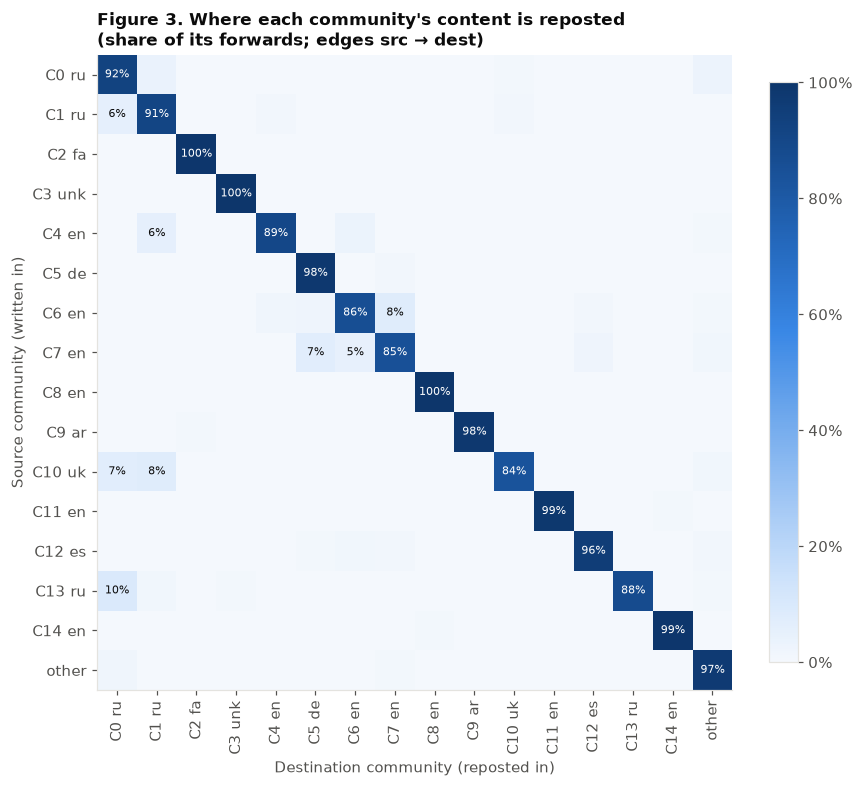

In [12]:
lang_major = ch.groupby("community").language.agg(lambda s: s.fillna("unk").value_counts().index[0])
keep = list(range(TOP))
M = graph.mixing_matrix(edges, c_of, keep)
names = [f"C{k} {lang_major[int(k)]}" if k != "other" else "other" for k in M.index]
R = M.div(M.sum(axis=1), axis=0)
M.set_axis(names, axis=0).set_axis(names, axis=1).to_csv(cfg.RESULTS / "02_mixing_counts.csv")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(R.to_numpy(), cmap=plots.blues_cmap(), vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90); ax.set_yticks(range(len(names)), names)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        v = R.iat[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.5 else plots.INK)
ax.set_xlabel("Destination community (reposted in)"); ax.set_ylabel("Source community (written in)")
ax.set_title("Figure 3. Where each community's content is reposted\n(share of its forwards; edges src → dest)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04, format=lambda v, _: f"{v:.0%}")
plots.savefig(fig, "02_fig3_mixing_matrix")
plt.show()

**Baseline crossing rates.** The share of forwards (and of edges) whose source and destination are in
different communities. The English–English row, and in particular its *text* forwards (the messages that
will receive topics), is the overall rate that RQ1 compares topics against.

In [13]:
def crossing(e, col="weight"):
    cross = e.src_id.map(c_of).to_numpy() != e.dest_id.map(c_of).to_numpy()
    return {"forwards": int(e[col].sum()), "crossing_forwards": int(e[col].to_numpy()[cross].sum()),
            "crossing_share": e[col].to_numpy()[cross].sum() / e[col].sum(),
            "edges": int((e[col] > 0).sum()), "crossing_edges": int(cross[e[col].to_numpy() > 0].sum()),
            "crossing_edge_share": cross[e[col].to_numpy() > 0].mean()}

base = pd.DataFrame({
    "full, all forwards": crossing(edges),
    "English–English, all forwards": crossing(edges_en),
    "English–English, text forwards": crossing(edges_en, "n_text"),
    "English–English, media forwards": crossing(edges_en, "n_media"),
}).T
base.to_csv(cfg.RESULTS / "02_baseline_crossing.csv")
base.style.format({"forwards": "{:,.0f}", "crossing_forwards": "{:,.0f}", "edges": "{:,.0f}",
                   "crossing_edges": "{:,.0f}", "crossing_share": "{:.1%}", "crossing_edge_share": "{:.1%}"})

,forwards,crossing_forwards,crossing_share,edges,crossing_edges,crossing_edge_share
"full, all forwards","57,947,677","3,459,111",6.0%,"4,676,642","586,566",12.5%
"English–English, all forwards","13,166,079","680,739",5.2%,"785,846","103,837",13.2%
"English–English, text forwards","7,731,006","386,975",5.0%,"711,022","90,257",12.7%
"English–English, media forwards","5,435,073","293,764",5.4%,"530,695","66,691",12.6%


## 6 · Crossings among English communities

**Figure 4.** English–English *text* forwards (the topic corpus) between the 12 full-graph communities
with the most English channels; all other communities are pooled as "other" (D13). Rows = source
community (written in), columns = destination (reposted in); each row sums to 100%. The diagonal (forwards
that stay inside) is grey with its share written in; colour shows only where the crossings go, on its own
scale. Labels give each community's share of conspiracy-labeled channels.

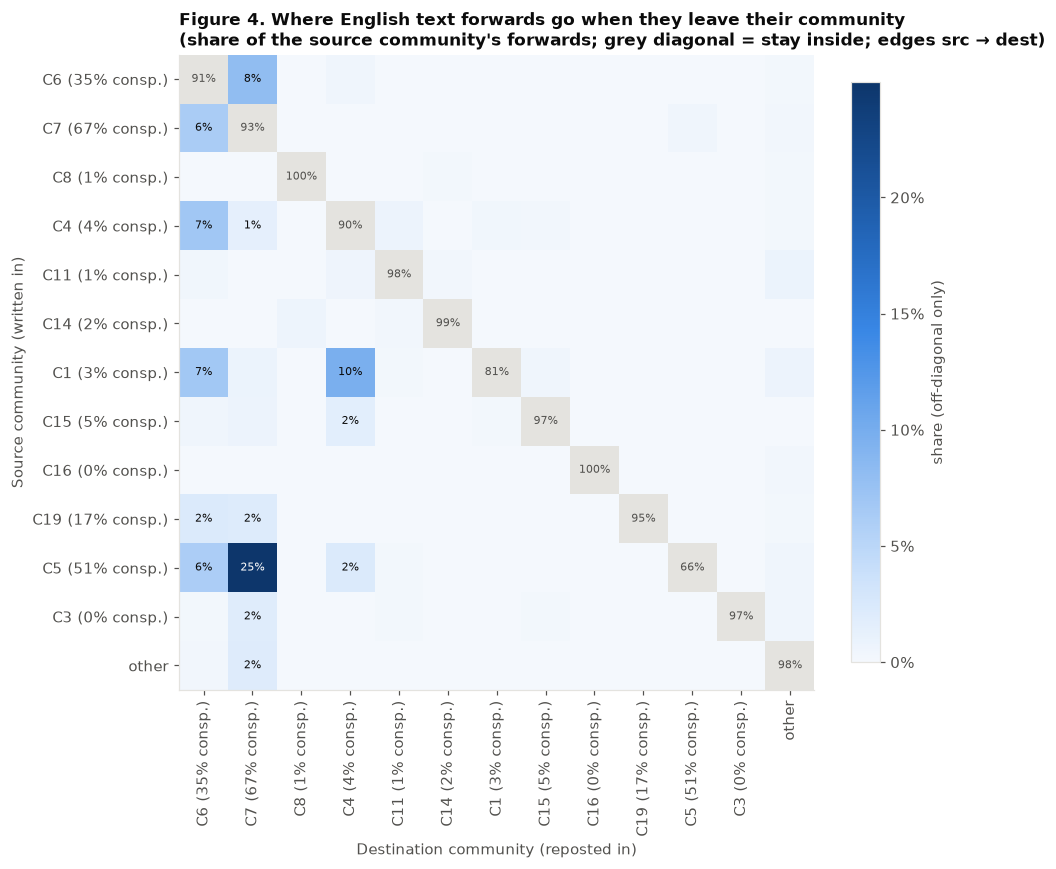

In [14]:
import igraph as ig

cons_of = channels.set_index("channel_id").conspiracy
cshare = ch.groupby("community").conspiracy.mean()
n_en = ch[ch.language == "en"].groupby("community").size().sort_values(ascending=False)
keep_en = n_en.index[:12].tolist()
txt = edges_en[edges_en.n_text > 0].assign(weight=lambda d: d.n_text)
M_en = graph.mixing_matrix(txt, c_of, keep_en)
names_en = [f"C{k} ({cshare[int(k)]:.0%} consp.)" if k != "other" else "other" for k in M_en.index]
R_en = M_en.div(M_en.sum(axis=1), axis=0)
M_en.set_axis(names_en, axis=0).set_axis(names_en, axis=1).to_csv(cfg.RESULTS / "02_mixing_en_text_counts.csv")

off = R_en.to_numpy().copy()
np.fill_diagonal(off, np.nan)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.set_facecolor("#e4e3df")
im = ax.imshow(np.ma.masked_invalid(off), cmap=plots.blues_cmap(), vmin=0, vmax=np.nanmax(off))
n = len(names_en)
ax.set_xticks(range(n), names_en, rotation=90); ax.set_yticks(range(n), names_en); ax.grid(False)
for i in range(n):
    ax.text(i, i, f"{R_en.iat[i, i]:.0%}", ha="center", va="center", fontsize=7, color=plots.INK_2)
    for j in range(n):
        v = off[i, j]
        if i != j and v >= 0.01:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 * np.nanmax(off) else plots.INK)
ax.set_xlabel("Destination community (reposted in)"); ax.set_ylabel("Source community (written in)")
ax.set_title("Figure 4. Where English text forwards go when they leave their community\n"
             "(share of the source community's forwards; grey diagonal = stay inside; edges src → dest)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04, format=lambda v, _: f"{v:.0%}", label="share (off-diagonal only)")
plots.savefig(fig, "02_fig4_mixing_en_offdiagonal")
plt.show()

## 7 · Conspiracy impurity of communities

How mixed each community is with respect to the published conspiracy label (D10). A community that is 0%
or 100% conspiracy is pure; 50% is maximally mixed (Gini impurity 2p(1−p) = 0.5).

channels                               120715.000000
conspiracy_channels                     11615.000000
conspiracy_share                            0.096218
gini_whole_graph                            0.173921
gini_within_communities                     0.113609
impurity_reduction                          0.346775
consp_in_majority_consp_communities         0.507189
consp_in_communities_under_10pct            0.219630


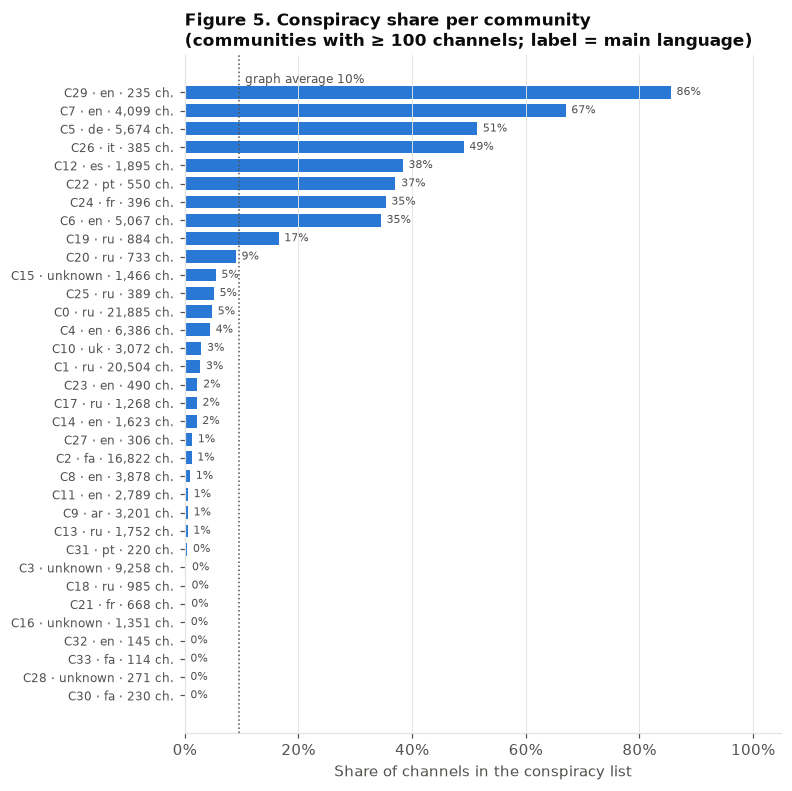

In [15]:
def composition(df, part_col="community"):
    comp = df.groupby(part_col).agg(channels=("channel_id", "size"), conspiracy=("conspiracy", "sum"),
                                    english=("language", lambda s: int((s == "en").sum())),
                                    languages=("language", mix))
    comp["conspiracy_share"] = comp.conspiracy / comp.channels
    comp["gini_impurity"] = 2 * comp.conspiracy_share * (1 - comp.conspiracy_share)
    return comp

def impurity_summary(df, comp):
    p = df.conspiracy.mean()
    within = (comp.gini_impurity * comp.channels).sum() / comp.channels.sum()
    c = comp[comp.conspiracy > 0]
    return {"channels": len(df), "conspiracy_channels": int(df.conspiracy.sum()), "conspiracy_share": p,
            "gini_whole_graph": 2 * p * (1 - p), "gini_within_communities": within,
            "impurity_reduction": 1 - within / (2 * p * (1 - p)),
            "consp_in_majority_consp_communities": c.conspiracy[c.conspiracy_share >= 0.5].sum() / c.conspiracy.sum(),
            "consp_in_communities_under_10pct": c.conspiracy[c.conspiracy_share < 0.1].sum() / c.conspiracy.sum()}

comp = composition(ch)
comp.to_csv(cfg.RESULTS / "02_community_conspiracy.csv")
imp = pd.Series(impurity_summary(ch, comp), name="full graph, all channels")
print(imp.to_string())

big = comp[comp.channels >= 100].sort_values("conspiracy_share")
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(range(len(big)), big.conspiracy_share, color=plots.SERIES[0], height=0.7)
ax.set_yticks(range(len(big)), [f"C{c} · {l.split(' ')[0]} · {n:,} ch." for c, l, n in
                                zip(big.index, big.languages, big.channels)], fontsize=8)
for i, v in enumerate(big.conspiracy_share):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=7, color=plots.INK_2)
ax.axvline(ch.conspiracy.mean(), color=plots.INK_2, ls=":", lw=1)
ax.text(ch.conspiracy.mean() + 0.01, len(big) - 0.5, f"graph average {ch.conspiracy.mean():.0%}",
        fontsize=8, color=plots.INK_2)
ax.set_xlim(0, 1.05); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of channels in the conspiracy list")
ax.set_title("Figure 5. Conspiracy share per community\n(communities with ≥ 100 channels; label = main language)", loc="left")
plots.savefig(fig, "02_fig5_conspiracy_share")
plt.show()

## 8 · Conspiracy × community: the four blocks

Each forward is classified by the label of its source and its destination: C→C, C→N, N→C, N→N
(C = conspiracy, N = not), separately for forwards that stay inside a community and forwards that cross
(D11). Counted in forwards and in edges. Edge direction: content flow (`src → dest`).

In [16]:
def blocks(e, col, part, unit="forwards"):
    w = e[col].to_numpy()
    w = (w > 0).astype("int64") if unit == "edges" else w
    sc, dc = e.src_id.map(cons_of).to_numpy(), e.dest_id.map(cons_of).to_numpy()
    cross = e.src_id.map(part).to_numpy() != e.dest_id.map(part).to_numpy()
    out = {}
    for name, mask in [("all", np.ones(len(e), bool)), ("within community", ~cross), ("across communities", cross)]:
        out[name] = {f"{'C' if a else 'N'}→{'C' if b else 'N'}": int(w[mask & (sc == a) & (dc == b)].sum())
                     for a in (True, False) for b in (True, False)}
    return pd.DataFrame(out).T

def show_blocks(counts):
    shares = counts.div(counts.sum(axis=1), axis=0)
    return counts.apply(lambda col: [f"{c:,} ({s:.1%})" for c, s in zip(col, shares[col.name])]).assign(
        total=counts.sum(axis=1).map("{:,}".format))

tabs = {
    ("English–English text", "forwards"): blocks(edges_en, "n_text", c_of),
    ("English–English text", "edges"): blocks(edges_en, "n_text", c_of, "edges"),
    ("full graph, all", "forwards"): blocks(edges, "weight", c_of),
    ("full graph, all", "edges"): blocks(edges, "weight", c_of, "edges"),
}
pd.concat(tabs, names=["scope", "unit", "subset"]).to_csv(cfg.RESULTS / "02_conspiracy_blocks.csv")
for (scope, unit), t in tabs.items():
    print(f"\n{scope}, counted in {unit} (row share in parentheses)")
    print(show_blocks(t).to_string())


English–English text, counted in forwards (row share in parentheses)
                                  C→C             C→N                N→C                N→N      total
all                 4,055,300 (52.5%)  221,594 (2.9%)  1,009,879 (13.1%)  2,444,233 (31.6%)  7,731,006
within community    3,783,202 (51.5%)  212,243 (2.9%)    928,446 (12.6%)  2,420,140 (33.0%)  7,344,031
across communities    272,098 (70.3%)    9,351 (2.4%)     81,433 (21.0%)      24,093 (6.2%)    386,975

English–English text, counted in edges (row share in parentheses)
                                C→C            C→N              N→C              N→N    total
all                 431,003 (60.6%)  33,064 (4.7%)  121,587 (17.1%)  125,368 (17.6%)  711,022
within community    366,433 (59.0%)  29,454 (4.7%)  104,953 (16.9%)  119,925 (19.3%)  620,765
across communities   64,570 (71.5%)   3,610 (4.0%)   16,634 (18.4%)     5,443 (6.0%)   90,257

full graph, all, counted in forwards (row share in parentheses)
          

                 all: conspiracy-sourced forwards that land in non-conspiracy channels: 5.2% of 4,276,894; non-conspiracy-sourced that land in conspiracy channels: 29.2%
    within community: conspiracy-sourced forwards that land in non-conspiracy channels: 5.3% of 3,995,445; non-conspiracy-sourced that land in conspiracy channels: 27.7%
  across communities: conspiracy-sourced forwards that land in non-conspiracy channels: 3.3% of 281,449; non-conspiracy-sourced that land in conspiracy channels: 77.2%

community-crossing English text forwards that involve a conspiracy channel at either end: 93.8% of 386,975


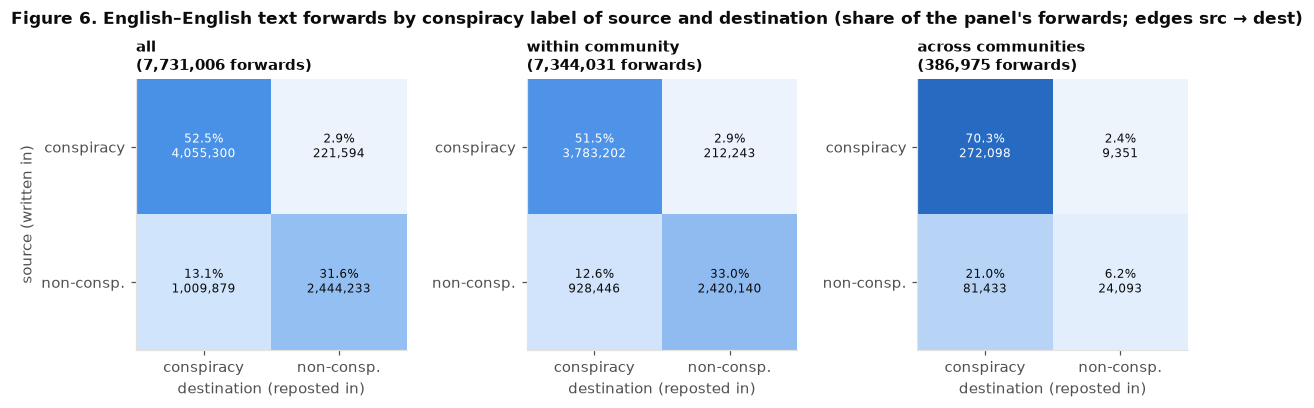

In [17]:
t = tabs[("English–English text", "forwards")]
for subset in ["all", "within community", "across communities"]:
    r = t.loc[subset]
    print(f"{subset:>20}: conspiracy-sourced forwards that land in non-conspiracy channels: "
          f"{r['C→N'] / (r['C→C'] + r['C→N']):.1%} of {r['C→C'] + r['C→N']:,}; "
          f"non-conspiracy-sourced that land in conspiracy channels: {r['N→C'] / (r['N→C'] + r['N→N']):.1%}")
x = t.loc["across communities"]
print(f"\ncommunity-crossing English text forwards that involve a conspiracy channel at either end: "
      f"{1 - x['N→N'] / x.sum():.1%} of {x.sum():,}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, subset in zip(axes, ["all", "within community", "across communities"]):
    r = t.loc[subset]
    mat = np.array([[r["C→C"], r["C→N"]], [r["N→C"], r["N→N"]]])
    sh = mat / mat.sum()
    ax.imshow(sh, cmap=plots.blues_cmap(), vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{sh[i, j]:.1%}\n{mat[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if sh[i, j] > 0.5 else plots.INK)
    ax.set_xticks([0, 1], ["conspiracy", "non-consp."]); ax.set_yticks([0, 1], ["conspiracy", "non-consp."])
    ax.grid(False); ax.set_xlabel("destination (reposted in)")
    ax.set_title(f"{subset}\n({mat.sum():,} forwards)", loc="left", fontsize=10)
axes[0].set_ylabel("source (written in)")
fig.suptitle("Figure 6. English–English text forwards by conspiracy label of source and destination "
             "(share of the panel's forwards; edges src → dest)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plots.savefig(fig, "02_fig6_conspiracy_blocks")
plt.show()

## 9 · How concentrated are the crossings? (diagnostic)

If a handful of edges or channels carried most of the community-crossing forwards, per-topic crossing
rates in RQ1 could reflect those channels rather than the topics (D12).

In [18]:
cross_en = edges_en.src_id.map(c_of).to_numpy() != edges_en.dest_id.map(c_of).to_numpy()
xe = edges_en[cross_en & (edges_en.n_text > 0)]
we = np.sort(xe.n_text.to_numpy())[::-1]
tot = we.sum()
print(f"English–English crossing text forwards: {tot:,} on {len(xe):,} edges, from {xe.src_id.nunique():,} source channels")
for k in (10, 100, 1000):
    print(f"  top {k:>5,} edges carry {we[:k].sum() / tot:.1%}")
by_src = xe.groupby("src_id").n_text.sum().sort_values(ascending=False)
for f, v in graph.top_share(by_src.to_numpy()).items():
    print(f"  top {f:.0%} of crossing sources ({max(1, round(f * len(by_src))):,} channels) carry {v:.1%}")

all_src = edges_en.groupby("src_id").n_text.sum()
top10 = by_src.index[:10]
rest = ~edges_en.src_id.isin(top10).to_numpy()
rate_all = tot / edges_en.n_text.sum()
rate_rest = edges_en.n_text.to_numpy()[rest & cross_en].sum() / edges_en.n_text.to_numpy()[rest].sum()
print(f"\ncrossing rate, all English text forwards: {rate_all:.2%}; without the 10 largest crossing sources: {rate_rest:.2%}")

top_cross = (pd.DataFrame({"crossing_text_forwards": by_src.head(15),
                           "share_of_all_crossing": by_src.head(15) / tot,
                           "share_of_own_text_forwards_crossing": (by_src / all_src.reindex(by_src.index)).head(15)})
             .join(info[["username", "ch_topic", "conspiracy"]]).join(c_of))
top_cross.to_csv(cfg.RESULTS / "02_top_crossing_sources.csv")
top_cross.style.format({"crossing_text_forwards": "{:,}", "share_of_all_crossing": "{:.1%}",
                        "share_of_own_text_forwards_crossing": "{:.0%}"})

English–English crossing text forwards: 386,975 on 90,257 edges, from 5,763 source channels
  top    10 edges carry 2.6%
  top   100 edges carry 11.6%
  top 1,000 edges carry 34.3%
  top 1% of crossing sources (58 channels) carry 48.3%
  top 5% of crossing sources (288 channels) carry 74.2%
  top 10% of crossing sources (576 channels) carry 84.0%

crossing rate, all English text forwards: 5.01%; without the 10 largest crossing sources: 3.99%


,crossing_text_forwards,share_of_all_crossing,share_of_own_text_forwards_crossing,username,ch_topic,conspiracy,community
src_id,,,,,,,
1179270258,"19,553",5.1%,17%,disclosetv,World news,False,7
1479163323,"13,284",3.4%,16%,TommyRobinsonNews,US news,True,7
1136479756,"11,143",2.9%,29%,police_frequency,US news,True,7
1310984791,"10,431",2.7%,55%,intelslava,World news,True,7
1335927003,"8,729",2.3%,32%,TheConspiracyHole,Covid,True,6
1387645188,"8,700",2.2%,12%,rtnews,World news,False,7
1459035940,"7,448",1.9%,32%,CovidRedPills,Covid,True,7
1392160803,"6,948",1.8%,25%,breaking911,US news,False,7
1235779695,"5,629",1.5%,48%,No_BS_NewS,US news,True,7


## 10 · Robustness: Leiden on the English–English graph only

Same settings as the main run, on the English–English graph (D9). Compared with the full-graph partition
restricted to the same English channels. The full graph stays the main boundary: it uses paths through
non-English channels (e.g. two English channels that both repost German channels), which the
English-only graph cannot see.

In [19]:
mem_en, meta_en = graph.leiden(g_en)
comm_en = pd.DataFrame({"channel_id": np.asarray(g_en.vs["channel_id"], dtype="int64"),
                        "community": mem_en.astype("int32")})
comm_en.to_parquet(cfg.DERIVED / "communities_en.parquet", index=False)
(cfg.DERIVED / "communities_en_meta.json").write_text(json.dumps(meta_en, indent=2))
(cfg.RESULTS / "02_leiden_run_en.json").write_text(json.dumps(meta_en, indent=2))
c_en_of = comm_en.set_index("channel_id").community

full_on_en = pd.factorize(c_of.reindex(comm_en.channel_id).to_numpy())[0]
sizes_en = comm_en.community.value_counts()
ch_en = comm_en.merge(channels, on="channel_id", how="left")
ch_full_en = ch_en.assign(community=full_on_en)
comp_en, comp_full_en = composition(ch_en), composition(ch_full_en)

def rate(part):
    c = edges_en.src_id.map(part).to_numpy() != edges_en.dest_id.map(part).to_numpy()
    return edges_en.n_text.to_numpy()[c].sum() / edges_en.n_text.sum(), c[edges_en.n_text.to_numpy() > 0].mean()

cmp = pd.DataFrame({
    "full-graph partition (main)": {
        "communities containing English channels": len(np.unique(full_on_en)),
        "… with ≥ 100 English channels": int((pd.Series(full_on_en).value_counts() >= 100).sum()),
        "directed modularity on the English graph": g_en.modularity(full_on_en.tolist(), weights="weight", directed=True),
        "crossing share, English text forwards": rate(c_of)[0],
        "crossing share, English text edges": rate(c_of)[1],
        "conspiracy impurity reduction": impurity_summary(ch_full_en, comp_full_en)["impurity_reduction"]},
    "English-only partition": {
        "communities containing English channels": meta_en["n_communities"],
        "… with ≥ 100 English channels": int((sizes_en >= 100).sum()),
        "directed modularity on the English graph": meta_en["modularity_directed"],
        "crossing share, English text forwards": rate(c_en_of)[0],
        "crossing share, English text edges": rate(c_en_of)[1],
        "conspiracy impurity reduction": impurity_summary(ch_en, comp_en)["impurity_reduction"]},
})
cmp.to_csv(cfg.RESULTS / "02_partition_comparison.csv")
print(f"Agreement between the two partitions on the {len(comm_en):,} English channels: "
      f"NMI = {ig.compare_communities(full_on_en.tolist(), mem_en.tolist(), method='nmi'):.3f}, "
      f"adjusted Rand = {ig.compare_communities(full_on_en.tolist(), mem_en.tolist(), method='adjusted_rand'):.3f}")
cmp

Agreement between the two partitions on the 18,216 English channels: NMI = 0.800, adjusted Rand = 0.762


,full-graph partition (main),English-only partition
communities containing English channels,74.000000,141.000000
… with ≥ 100 English channels,16.000000,17.000000
directed modularity on the English graph,0.722508,0.737190
"crossing share, English text forwards",0.050055,0.101945
"crossing share, English text edges",0.126940,0.243759
conspiracy impurity reduction,0.385386,0.382293


In [20]:
# How the largest English-only communities map onto the full-graph communities
rows = []
for c in range(12):
    m = ch_en[ch_en.community == c]
    fc = c_of.reindex(m.channel_id).value_counts()
    rows.append({"en_community": c, "channels": len(m), "conspiracy_share": m.conspiracy.mean(),
                 "english_topics": mix(m.ch_topic.dropna()),
                 "main_full_community": f"C{fc.index[0]}", "overlap": fc.iloc[0] / len(m),
                 "second_full_community": f"C{fc.index[1]} ({fc.iloc[1] / len(m):.0%})" if len(fc) > 1 else "",
                 "top_reposted": top_names(m.merge(nodes_en, on="channel_id"), "out_strength")})
map_en = pd.DataFrame(rows).set_index("en_community")
map_en.to_csv(cfg.RESULTS / "02_en_communities_vs_full.csv")
x = blocks(edges_en, "n_text", c_en_of).loc["across communities"]
print(f"English-only partition: community-crossing text forwards involving a conspiracy channel: "
      f"{1 - x['N→N'] / x.sum():.1%} of {x.sum():,}")
map_en.style.format({"conspiracy_share": "{:.0%}", "overlap": "{:.0%}", "channels": "{:,}"})

English-only partition: community-crossing text forwards involving a conspiracy channel: 97.3% of 788,141


,channels,conspiracy_share,english_topics,main_full_community,overlap,second_full_community,top_reposted
en_community,,,,,,,
0,"3,896",40%,"Religion 42%, Extremists and radicals 21%, US news 15%",C6,93%,C4 (2%),"HawGa, BellumActaNews, TheConspiracyHole"
1,"2,960",1%,"Videogame modding 48%, Carding 42%, Software 6%",C8,100%,C32 (0%),"followersmart1, PUBG_ACCOUNT_OFFICAL, UC_SH0PS"
2,"2,294",66%,"US news 72%, Religion 13%, Covid 9%",C7,97%,C5 (2%),"disclosetv, realKarliBonne, rtnews"
3,"1,990",8%,"Religion 40%, Entertainment 34%, World news 6%",C4,87%,C1 (9%),"dadoem_mv, applebeas, HourlyFoxes"
4,"1,575",1%,"Religion 75%, Entertainment 9%, Indian edu 5%",C11,75%,C9 (10%),"memespundit, middnightthoughts, sosavage_memes"
5,"1,361",71%,"Covid 70%, US news 13%, Religion 6%",C7,93%,C6 (3%),"davidavocadowolfe, CovidRedPills, JustDudeChannel"
6,791,3%,"Porn 65%, Religion 16%, Entertainment 7%",C14,98%,C11 (1%),"Psychothreat, Bettingarenaah, kiddiesporn"
7,659,4%,"Software 47%, World news 17%, Entertainment 12%",C15,73%,C1 (14%),"internationalfccp, sohusatoday, hacker_news_feed"
8,325,59%,"World news 30%, US news 26%, Religion 17%",C6,70%,C7 (25%),"TommyRobinsonNews, JackDawkins, therealityreport"


## 11 · Numbers for the progress report

Collected from the cells above, with denominators.

In [21]:
s, s_en = summary["full"], summary["english_english"]
b = base.loc["English–English, text forwards"]
print(f'''Full graph: {s.nodes:,.0f} channels, {s.edges:,.0f} edges, {s.forwards:,.0f} channel-to-channel forwards
  (of 93,421,020 forwarded messages; the rest have a hidden sender, a source outside the dataset, or are self-forwards).
  Largest weakly connected component: {s.largest_wcc_share:.1%} of channels; largest strongly connected: {s.largest_scc_share:.1%}.
  Reciprocity: {s.reciprocity_edges:.1%} of edges, {s.reciprocity_weighted:.1%} of forward volume.
  Top 1% / 5% of channels by times reposted are the source of {conc.loc["top 1% of sources", ("full", "all graph nodes")]:.0%} / {conc.loc["top 5% of sources", ("full", "all graph nodes")]:.0%} of forwards.
English–English graph: {s_en.nodes:,.0f} channels, {s_en.edges:,.0f} edges, {s_en.forwards:,.0f} forwards.
Leiden (resolution 1.0, seed 42): {meta["n_communities"]:,} communities; directed modularity {meta["modularity_directed"]:.3f}
  (undirected {meta["modularity_undirected"]:.3f}; TGDataset reports 0.78).
  Sabmyk: {modal.iloc[0]} of {len(sab)} channels in one community.
Baseline: {b.crossing_share:.1%} of English–English text forwards ({b.crossing_forwards:,.0f} of {b.forwards:,.0f}) cross a community boundary.''')

Full graph: 120,715 channels, 4,676,642 edges, 57,947,677 channel-to-channel forwards
  (of 93,421,020 forwarded messages; the rest have a hidden sender, a source outside the dataset, or are self-forwards).
  Largest weakly connected component: 100.0% of channels; largest strongly connected: 74.6%.
  Reciprocity: 18.6% of edges, 12.0% of forward volume.
  Top 1% / 5% of channels by times reposted are the source of 43% / 70% of forwards.
English–English graph: 18,216 channels, 785,846 edges, 13,166,079 forwards.
Leiden (resolution 1.0, seed 42): 289 communities; directed modularity 0.862
  (undirected 0.862; TGDataset reports 0.78).
  Sabmyk: 234 of 236 channels in one community.
Baseline: 5.0% of English–English text forwards (386,975 of 7,731,006) cross a community boundary.
